# Riesgo de rotura priorizado por margen y cohortes
Responsable: Persona 3 · Entrega 1 · Requiere `uv run novaretail all` antes de ejecutar.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd() / "src", Path.cwd().parent / "src"]:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import pandas as pd
import matplotlib.pyplot as plt
from novaretail import cohorts, stock
from novaretail.config import CLEAN, FIGURES

FIGURES.mkdir(parents=True, exist_ok=True)
inventory = pd.read_parquet(CLEAN / "inventory_weekly.parquet")
sales = pd.read_parquet(CLEAN / "sales.parquet")
products = pd.read_parquet(CLEAN / "products.parquet")
stores = pd.read_parquet(CLEAN / "stores.parquet")
orders = pd.read_parquet(CLEAN / "orders.parquet")
customers = pd.read_parquet(CLEAN / "customers.parquet")

## 1. Riesgo de rotura de stock y margen en riesgo

In [2]:
risk = stock.stockout_risk(inventory, sales, products)
risk = risk.merge(stores[["store_id", "store_name", "region", "format"]], on="store_id", how="left")

print(f"Margen total en riesgo semanal: {risk['margin_at_risk_eur'].sum():,.2f} €")
print(f"Margen en riesgo en combinaciones a reponer esta semana: {risk.loc[risk['reorder_now'], 'margin_at_risk_eur'].sum():,.2f} €")
print(f"Combinaciones a reponer esta semana: {risk['reorder_now'].sum()} de {len(risk)}")

region_summary = (
    risk.groupby("region", as_index=False)
    .agg(combinaciones=("product_id", "count"), a_reponer=("reorder_now", "sum"),
         unidades_a_pedir=("recommended_order_units", "sum"), margen_en_riesgo_eur=("margin_at_risk_eur", "sum"))
    .sort_values("margen_en_riesgo_eur", ascending=False)
)
display(region_summary)
display(risk.head(15))

Margen total en riesgo semanal: 23,881.20 €
Margen en riesgo en combinaciones a reponer esta semana: 2,917.27 €
Combinaciones a reponer esta semana: 34 de 5219


,region,combinaciones,a_reponer,unidades_a_pedir,margen_en_riesgo_eur
3,Sur,1452,15,115,7261.39
1,Este,1142,4,35,5745.60
0,Centro,1347,7,74,5637.25
2,Norte,1278,8,59,5236.96


,store_id,product_id,product_name,category,week,on_hand_units,on_order_units,lead_time_days,lead_time_weeks,expected_weekly_demand,coverage_weeks,stockout_prob,unit_margin_eur,demand_lead_time_units,margin_at_risk_eur,reorder_now,recommended_order_units,store_name,region,format
0,S028,P0124,Zapatillas Kairo Lite,Moda,2026-10-26,13,21,20,2.86,8.580050,3.96,0.3414,40.31,24.54,337.72,False,0,NovaRetail Valencia 08,Este,express
1,S027,P0124,Zapatillas Kairo Lite,Moda,2026-10-26,2,52,24,3.43,9.426766,5.73,0.2383,40.31,32.33,310.56,False,0,NovaRetail Barcelona 07,Este,express
2,S012,P0136,Camisa Alba Eco,Moda,2026-10-26,3,6,22,3.14,4.480536,2.01,0.6095,27.97,14.07,239.86,True,15,NovaRetail Málaga 02,Sur,estandar
3,S030,P0002,Altavoz Marea Eco,Electronica,2026-10-26,7,0,17,2.43,2.624818,2.67,0.4858,68.77,6.38,213.15,False,0,NovaRetail Barcelona 10,Este,estandar
4,S013,P0194,Camara Novatek Eco,Electronica,2026-10-26,4,0,19,2.71,2.603650,1.54,0.5656,53.22,7.06,212.51,True,9,NovaRetail Granada 03,Sur,estandar
5,S010,P0355,Teclado Novatek,Electronica,2026-10-26,14,0,15,2.14,5.411923,2.59,0.4565,37.22,11.58,196.75,False,0,NovaRetail Bilbao 10,Norte,outlet
6,S033,P0355,Teclado Novatek,Electronica,2026-10-26,16,0,18,2.57,4.565208,3.50,0.3979,37.22,11.73,173.72,False,0,NovaRetail Valladolid 03,Centro,estandar
7,S040,P0223,Camisa Zentro Mini,Moda,2026-10-26,9,0,23,3.29,3.485645,2.58,0.5362,26.98,11.47,165.93,True,10,NovaRetail Madrid 10,Centro,estandar
8,S007,P0052,Esterilla Lumen Lite,Deportes,2026-10-26,8,0,12,1.71,5.277860,1.52,0.5241,34.33,9.03,162.47,True,12,NovaRetail Bilbao 07,Norte,estandar
9,S021,P0189,Esterilla Sierra Mini,Deportes,2026-10-26,12,17,14,2.00,7.084186,4.09,0.2866,39.64,14.17,160.98,False,0,NovaRetail Barcelona 01,Este,flagship


## 2. Recomendación táctica: dónde reponer esta semana

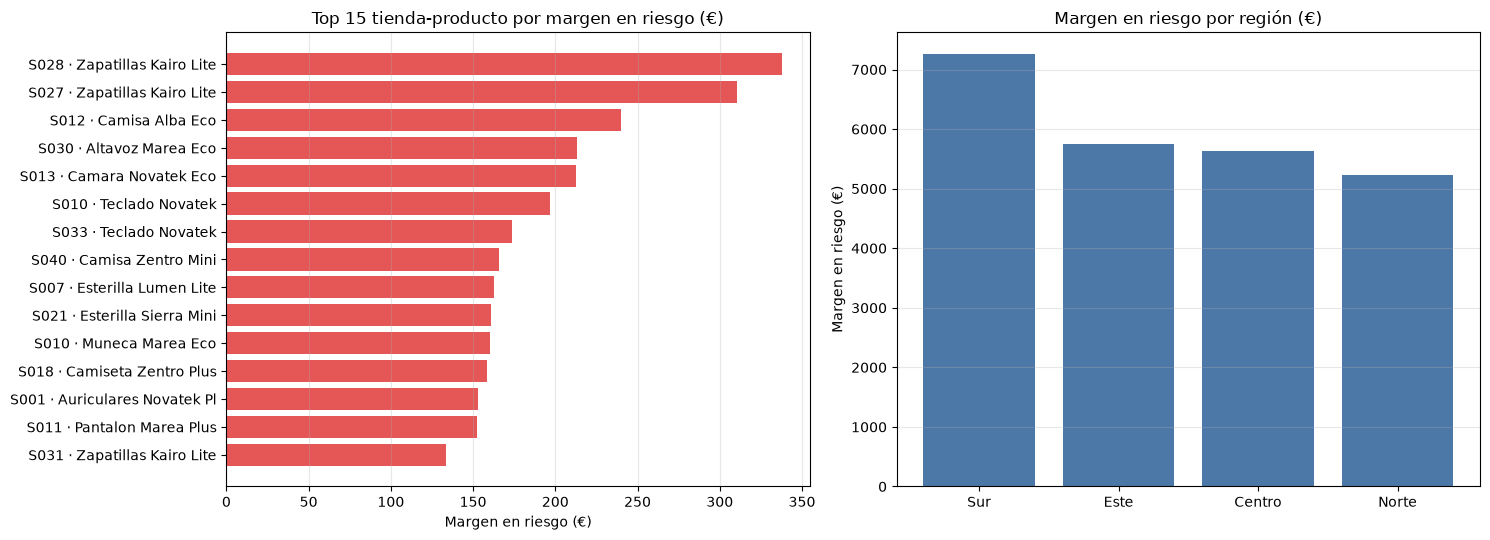

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top15 = risk.head(15).copy()
top15["label"] = top15["store_id"] + " · " + top15["product_name"].str.slice(0, 22)
top15 = top15.iloc[::-1]
axes[0].barh(top15["label"], top15["margin_at_risk_eur"], color="#E45756")
axes[0].set_title("Top 15 tienda-producto por margen en riesgo (€)")
axes[0].set_xlabel("Margen en riesgo (€)")
axes[0].grid(axis="x", alpha=0.3)

axes[1].bar(region_summary["region"], region_summary["margen_en_riesgo_eur"], color="#4C78A8")
axes[1].set_title("Margen en riesgo por región (€)")
axes[1].set_ylabel("Margen en riesgo (€)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES / "stock_top_margen_riesgo.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Matriz de cohortes por canal de adquisición

month_offset,1,2,3,4,5,6,media_M1_M6
acquisition_channel,,,,,,,
referido,12.31,12.03,11.72,14.23,8.57,8.83,11.28
app,13.87,11.70,11.06,10.26,10.29,10.25,11.24
web,12.43,12.00,11.59,10.74,9.93,10.60,11.21
tienda,12.45,12.17,11.77,10.32,10.09,10.02,11.14
marketplace,12.48,11.91,10.85,9.53,9.69,10.11,10.76
redes_sociales,11.88,11.50,11.30,11.21,9.29,8.29,10.58


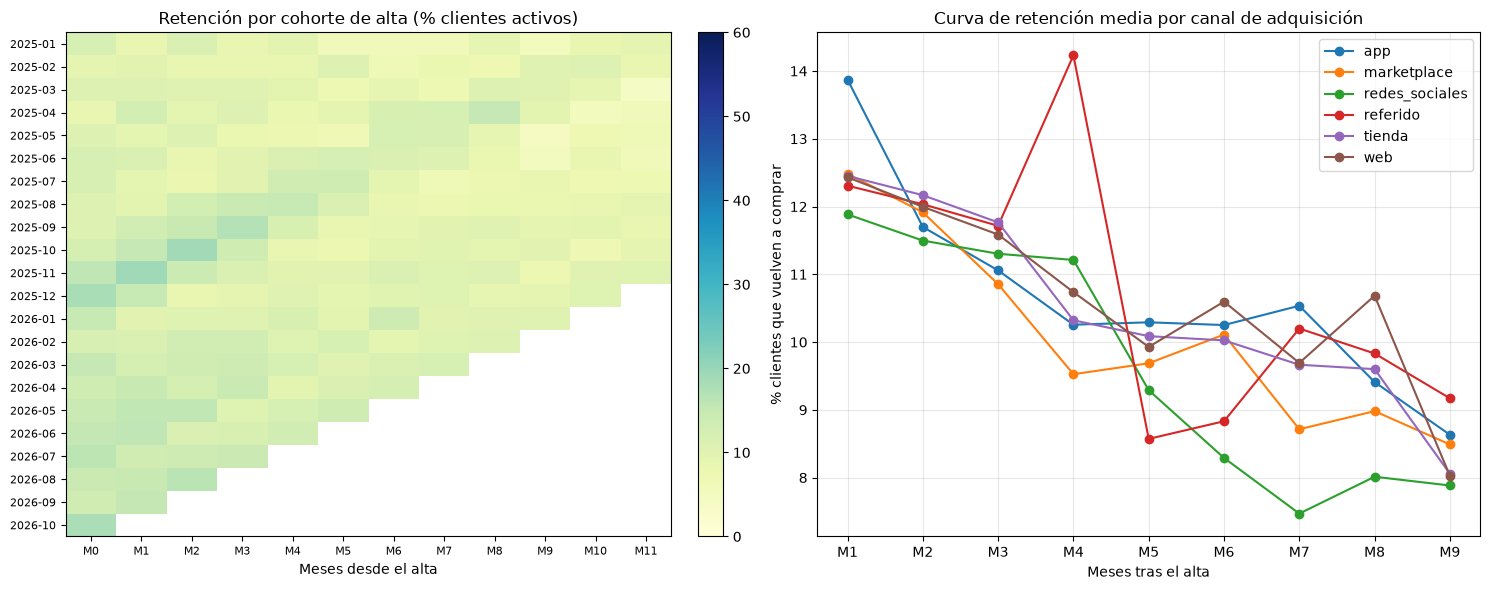

In [4]:
ret_global = cohorts.retention_matrix(orders, customers, by=None)
ret_by_ch = cohorts.retention_matrix(orders, customers, by="acquisition_channel")

cols_1_6 = [c for c in [1, 2, 3, 4, 5, 6] if c in ret_by_ch.columns]
ch_retention_summary = ret_by_ch[cols_1_6].groupby(level=0).mean().round(2)
ch_retention_summary["media_M1_M6"] = ch_retention_summary.mean(axis=1).round(2)
display(ch_retention_summary.sort_values("media_M1_M6", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
mat_plot = ret_global.iloc[:, :12]
im = axes[0].imshow(mat_plot.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=60)
axes[0].set_yticks(range(len(mat_plot.index)))
axes[0].set_yticklabels(mat_plot.index, fontsize=8)
axes[0].set_xticks(range(len(mat_plot.columns)))
axes[0].set_xticklabels([f"M{c}" for c in mat_plot.columns], fontsize=8)
axes[0].set_title("Retención por cohorte de alta (% clientes activos)")
axes[0].set_xlabel("Meses desde el alta")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

mean_curves = ret_by_ch.iloc[:, 1:10].groupby(level=0).mean()
for ch in mean_curves.index:
    axes[1].plot([f"M{c}" for c in mean_curves.columns], mean_curves.loc[ch], marker="o", label=ch)
axes[1].set_title("Curva de retención media por canal de adquisición")
axes[1].set_ylabel("% clientes que vuelven a comprar")
axes[1].set_xlabel("Meses tras el alta")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES / "cohortes_retencion_canal.png", dpi=200, bbox_inches="tight")
plt.show()